## **EDA of Titanic dataset**

In [22]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# **Ex 1**

In [2]:
#Ex. 1
# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


In [76]:
df = pd.read_csv(path+"/Titanic-Dataset.csv")

#count non-mssing values in each column
df.count()

,0
PassengerId,891
Survived,891
Pclass,891
Name,891
Sex,891
Age,714
SibSp,891
Parch,891
Ticket,891
Fare,891


In [86]:
print(df.tail(3))
print(df.columns)
print(df.dtypes)

     Survived  Pclass     Sex   Age  SibSp  Parch   Fare Embarked age_group
888         0       3  female  21.5      1      2  23.45        S       NaN
889         1       1    male  26.0      0      0  30.00        C     young
890         0       3    male  32.0      0      0   7.75        Q     young
Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'age_group'],
      dtype='object')
Survived        int64
Pclass          int64
Sex            object
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Embarked       object
age_group    category
dtype: object


In [87]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.112424,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.304424,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,21.500000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,36.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


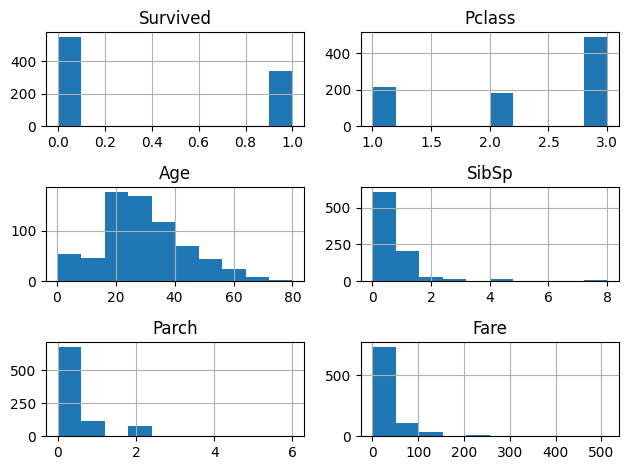

In [58]:
df.hist()
plt.tight_layout()
plt.show()

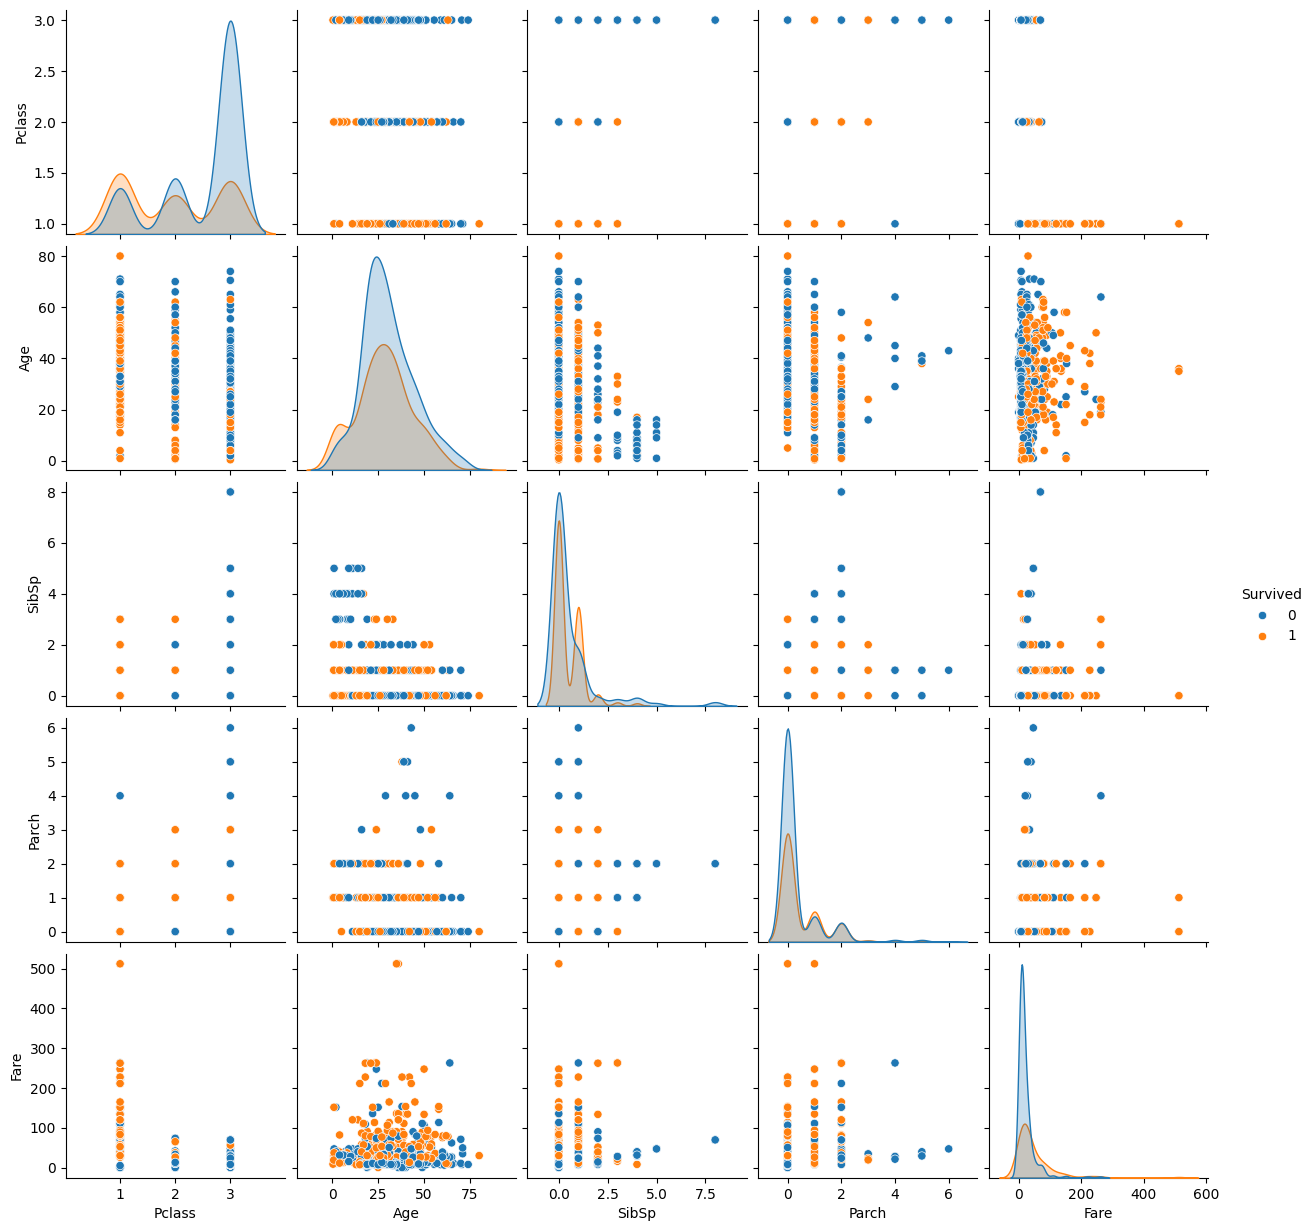

In [60]:
sns.pairplot(df, hue="Survived")

# **Ex 2**

In [61]:
# Ex. 2
df_sex_class = df.groupby(['Sex', 'Pclass'])
print(df_sex_class['Survived'].mean())
print(df_sex_class.describe())

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64
              Survived                                                 Age  \
                 count      mean       std  min  25%  50%  75%  max  count   
Sex    Pclass                                                                
female 1          94.0  0.968085  0.176716  0.0  1.0  1.0  1.0  1.0   85.0   
       2          76.0  0.921053  0.271448  0.0  1.0  1.0  1.0  1.0   74.0   
       3         144.0  0.500000  0.501745  0.0  0.0  0.5  1.0  1.0  102.0   
male   1         122.0  0.368852  0.484484  0.0  0.0  0.0  1.0  1.0  101.0   
       2         108.0  0.157407  0.365882  0.0  0.0  0.0  0.0  1.0   99.0   
       3         347.0  0.135447  0.342694  0.0  0.0  0.0  0.0  1.0  253.0   

                          ... Parch        Fare                         \
               

In [80]:
bins = [0, 13, 20, 35, 60, 100]
labels = ['child', 'teenager', 'young', 'adult', 'senior']
df['age_group'] = pd.cut(df['Age'], bins=bins, labels=labels)
survival_age = df.groupby('age_group', observed=False)
print(survival_age.describe())

          Survived                                              Pclass  \
             count      mean       std  min  25%  50%  75%  max  count   
age_group                                                                
child         71.0  0.591549  0.495046  0.0  0.0  1.0  1.0  1.0   71.0   
teenager     108.0  0.370370  0.485155  0.0  0.0  0.0  1.0  1.0  108.0   
young        318.0  0.393082  0.489205  0.0  0.0  0.0  1.0  1.0  318.0   
adult        195.0  0.400000  0.491159  0.0  0.0  0.0  1.0  1.0  195.0   
senior        22.0  0.227273  0.428932  0.0  0.0  0.0  0.0  1.0   22.0   

                     ... Parch        Fare                                \
               mean  ...   75%  max  count       mean        std     min   
age_group            ...                                                   
child      2.633803  ...   2.0  2.0   71.0  31.024472  26.241050  7.2292   
teenager   2.527778  ...   0.0  3.0  108.0  29.082988  48.851646  0.0000   
young      2.339623  ...   

In [88]:
age_stats = df.groupby('age_group', observed=False).agg({
    'Survived': 'mean',
    'Fare': ['mean', 'median'],
    'Pclass': 'count'
})
age_stats.columns = ['Survival Rate', 'Avg Fare', 'Median Fare', 'Passenger count']
print(age_stats)

           Survival Rate   Avg Fare  Median Fare  Passenger count
age_group                                                        
child           0.591549  31.024472     26.25000               71
teenager        0.370370  29.082988      9.83335              108
young           0.393082  31.092398     13.00000              318
adult           0.400000  44.259658     26.28750              195
senior          0.227273  41.371214     26.55000               22


/tmp/ipython-input-3008074515.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='age_group', y='Survived', palette='viridis')


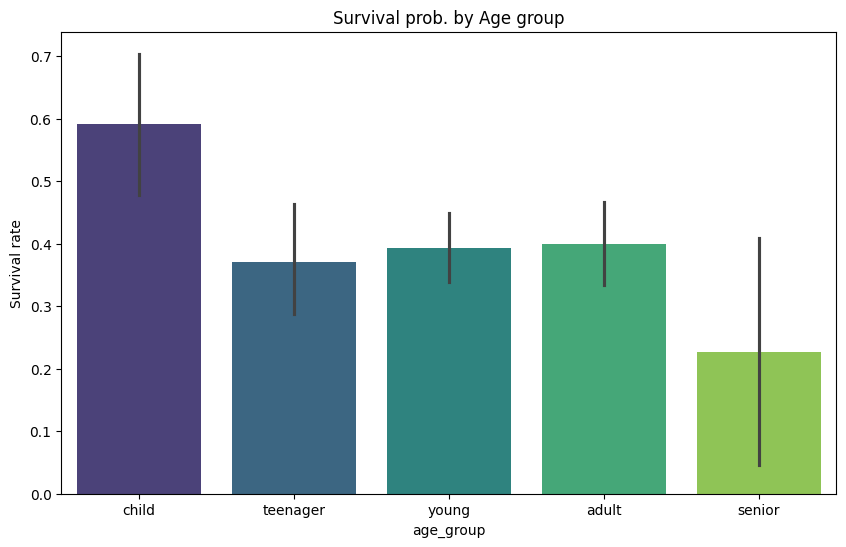

In [64]:
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='age_group', y='Survived', palette='viridis')
plt.title('Survival prob. by Age group')
plt.ylabel('Survival rate')
plt.show()

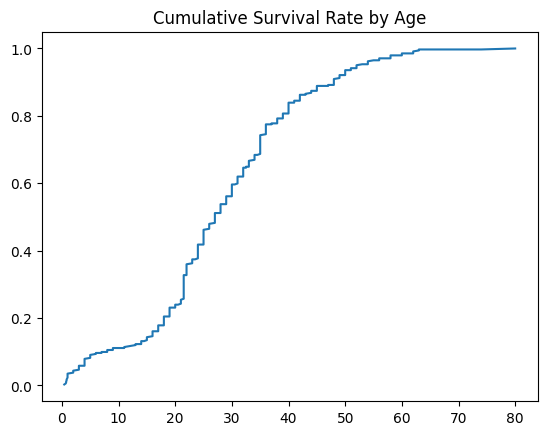

In [156]:
df = df.sort_values('Age')
df['cumulative_survival'] = df['Survived'].cumsum() / df['Survived'].sum()
plt.plot(df['Age'], df['cumulative_survival'])
plt.title('Cumulative Survival Rate by Age')
plt.show()

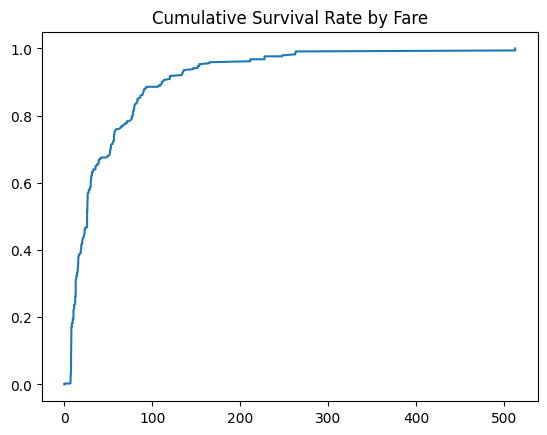

In [155]:
df = df.sort_values('Fare')
df['cumulative_survival'] = df['Survived'].cumsum() / df['Survived'].sum()
plt.plot(df['Fare'], df['cumulative_survival'])
plt.title('Cumulative Survival Rate by Fare')
plt.show()

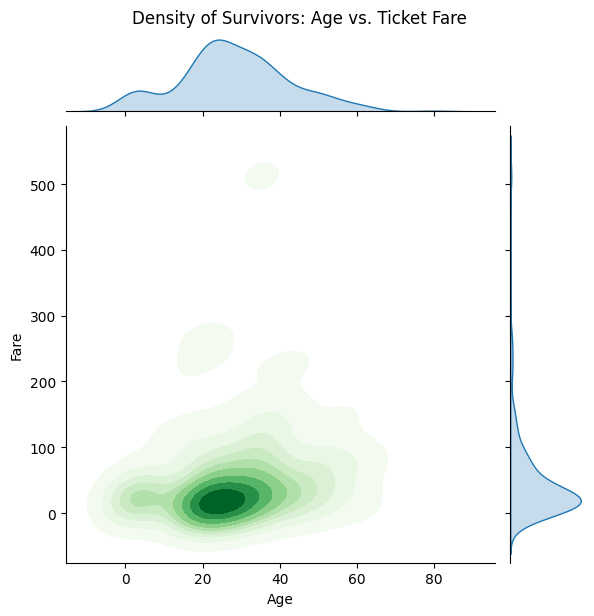

In [114]:
df_age_fare_no_na = df.dropna(subset=['Age','Fare'])
g = sns.jointplot(
    data=df_age_fare_no_na[df_age_fare_no_na['Survived'] == 1],
    x='Age',
    y='Fare',
    kind='kde',
    fill=True,
    cmap="Greens"
)
g.fig.suptitle('Density of Survivors: Age vs. Ticket Fare', y=1.02)
plt.show()

# **Ex 3**

In [89]:
#Ex. 3
unique_counts = df.nunique()
print(unique_counts)
pivot_df = df.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean')
print(pivot_df)

Survived       2
Pclass         3
Sex            2
Age           89
SibSp          7
Parch          7
Fare         248
Embarked       3
age_group      5
dtype: int64
Pclass         1         2         3
Sex                                 
female  0.968085  0.921053  0.500000
male    0.368852  0.157407  0.135447


# **Ex 4**

In [82]:
#Ex 4
df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], inplace=True)
df.count()

KeyError: "['PassengerId', 'Name', 'Ticket', 'Cabin'] not found in axis"

In [85]:
df['Age'] = df['Age'].fillna(df.groupby(['Pclass', 'Sex'])['Age'].transform('median'))
#fill embarked with the most common mode of three modes
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df.count()

,0
Survived,891
Pclass,891
Sex,891
Age,891
SibSp,891
Parch,891
Fare,891
Embarked,891
age_group,714


**Feature engineering**

In [92]:
df['family_size'] = df['SibSp'] + df['Parch']
print(df.count())
df.describe()

Survived       891
Pclass         891
Sex            891
Age            891
SibSp          891
Parch          891
Fare           891
Embarked       891
age_group      714
family_size    891
dtype: int64


,Survived,Pclass,Age,SibSp,Parch,Fare,family_size
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.112424,0.523008,0.381594,32.204208,0.904602
std,0.486592,0.836071,13.304424,1.102743,0.806057,49.693429,1.613459
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,21.500000,0.000000,0.000000,7.910400,0.000000
50%,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200,0.000000
75%,1.000000,3.000000,36.000000,1.000000,0.000000,31.000000,1.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,10.000000


**Encoding sex for ML**

In [93]:
df['sex_encoded'] = df['Sex'].map({'male': 0, 'female': 1})
df.count()

,0
Survived,891
Pclass,891
Sex,891
Age,891
SibSp,891
Parch,891
Fare,891
Embarked,891
age_group,714
family_size,891


# **Ex. 5 - Different Supervised classifiers**

In [157]:
#Ex. 5
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import RocCurveDisplay


In [97]:
features = ['Pclass', 'Age', 'family_size', 'Fare', 'sex_encoded']
X = df[features]
y = df['Survived']


In [98]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [99]:
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

In [102]:
# Lasso logistic regression
model = LogisticRegression(penalty='l1', solver='liblinear', C=1.0)
model.fit(X_train_scaled, y_train)


LogisticRegression(penalty='l1', solver='liblinear')

In [105]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.80
Testing accuracy:  0.82


In [106]:
importance = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
})
print(importance.sort_values(by='Coefficient', ascending=False))


       Feature  Coefficient
4  sex_encoded     1.280180
3         Fare     0.152219
2  family_size    -0.404639
1          Age    -0.447196
0       Pclass    -0.842858


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


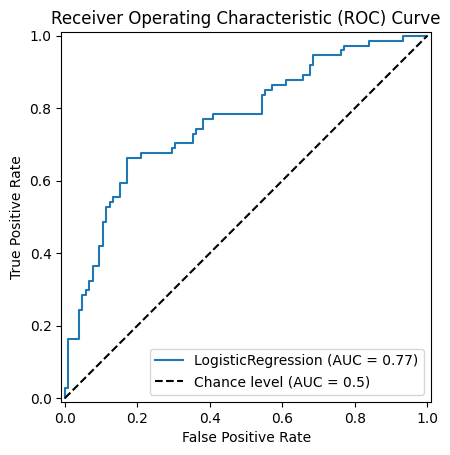

In [158]:
RocCurveDisplay.from_estimator(model, X_test, y_test)

plt.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)') # Add chance level line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [145]:
# Elasticnet logistic regression
model = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=1.0, max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(l1_ratio=0.5, max_iter=1000, penalty='elasticnet',
                   solver='saga')

In [146]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.80
Testing accuracy:  0.83


In [137]:
importance = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
})
print(importance.sort_values(by='Coefficient', ascending=False))


       Feature  Coefficient
4  sex_encoded     1.281415
3         Fare     0.157920
2  family_size    -0.411155
1          Age    -0.453063
0       Pclass    -0.844502


In [153]:
# Grid Search
param_grid = {
    'C': [0.001, 0.01, 0.1, 0.2, 0.3, 0.5, 1, 10],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9, 0.95, 1.0]
}
grid_search = GridSearchCV(
    LogisticRegression(penalty='elasticnet', solver='saga', max_iter=10000),
    param_grid,
    cv=4,
    scoring='accuracy'
)

grid_search.fit(X_train_scaled, y_train)

# Print best parameters
print(f"Best parameters: {grid_search.best_params_}")

# Use the best model
best_model = grid_search.best_estimator_


Best parameters: {'C': 0.5, 'l1_ratio': 0.7}


In [154]:
print(f"Training accuracy: {best_model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {best_model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.80
Testing accuracy:  0.82


In [117]:
# SVM
model = svm.SVC(kernel='linear', C=1)
model.fit(X_train_scaled, y_train)

SVC(C=1, kernel='linear')

In [118]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.79
Testing accuracy:  0.78


In [119]:
importance = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
})
print(importance.sort_values(by='Coefficient', ascending=False))


       Feature  Coefficient
4  sex_encoded     0.950190
3         Fare     0.000482
0       Pclass    -0.000033
1          Age    -0.000248
2  family_size    -0.000715


In [133]:
# KNN
model = KNeighborsClassifier(n_neighbors=10)
model.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=10)

In [134]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.85
Testing accuracy:  0.81


# **Ex 6**

In [112]:
first_class_teens = df[(df['Pclass'] == 1) & (df['age_group'] == 'teenager')]
print(first_class_teens.describe())
first_class_teens.count()

        Survived  Pclass        Age      SibSp      Parch        Fare  \
count  17.000000    17.0  17.000000  17.000000  17.000000   17.000000   
mean    0.823529     1.0  17.352941   0.705882   0.882353  113.759559   
std     0.392953     0.0   1.538716   0.848875   0.927520   78.878253   
min     0.000000     1.0  14.000000   0.000000   0.000000   26.283300   
25%     1.000000     1.0  16.000000   0.000000   0.000000   57.000000   
50%     1.000000     1.0  18.000000   1.000000   1.000000   91.079200   
75%     1.000000     1.0  19.000000   1.000000   2.000000  120.000000   
max     1.000000     1.0  19.000000   3.000000   2.000000  263.000000   

       family_size  sex_encoded  
count    17.000000    17.000000  
mean      1.588235     0.764706  
std       1.325652     0.437237  
min       0.000000     0.000000  
25%       1.000000     1.000000  
50%       1.000000     1.000000  
75%       2.000000     1.000000  
max       5.000000     1.000000  


,0
Survived,17
Pclass,17
Sex,17
Age,17
SibSp,17
Parch,17
Fare,17
Embarked,17
age_group,17
family_size,17
